
## Práctica guiada en Python


## 1. Preparar el entorno y el corpus

In [61]:
import re
from collections import Counter

corpus = [
    "¡El servicio al cliente es excelente y muy rápido en la entrega!",
    "El servicio es pésimo y la atención al cliente es muy lenta.",
    "Excelente atención pero el servicio de entrega es lento.",
]

print("Librerías listas")
for i, d in enumerate(corpus, start=1):
    print(f"D{i}: {d}")

Librerías listas
D1: ¡El servicio al cliente es excelente y muy rápido en la entrega!
D2: El servicio es pésimo y la atención al cliente es muy lenta.
D3: Excelente atención pero el servicio de entrega es lento.


## 2. Limpiar HTML y ruido

Primero quito etiquetas HTML, enlaces, correos y emojis. Después normalizo los espacios.

### Quitar etiquetas HTML

In [62]:
sucio = "<p>¡El <b>servicio</b> al cliente es <i>excelente</i>!</p>"
limpio_html = re.sub(r"<[^>]+>", "", sucio)
print(sucio)
print(limpio_html)

<p>¡El <b>servicio</b> al cliente es <i>excelente</i>!</p>
¡El servicio al cliente es excelente!


### Quitar URLs, correos, emojis y espacios repetidos

In [63]:
ruido = "Visítanos en https://ejemplo.com o escríbenos a info@ejemplo.com ☺ ¡Gracias!"
ruido = re.sub(r"https?://\S+", "", ruido)
ruido = re.sub(r"\S+@\S+", "", ruido)
ruido = re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", "", ruido)
ruido = re.sub(r"\s+", " ", ruido).strip()
print(ruido)

Visítanos en o escríbenos a ¡Gracias!


### Reunir la limpieza en una función

In [64]:
def limpiar_html_y_ruido(texto):
    texto = re.sub(r"<[^>]+>", "", texto)  # etiquetas HTML
    texto = re.sub(r"https?://\S+", "", texto)  # URLs
    texto = re.sub(r"\S+@\S+", "", texto)  # correos
    texto = re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", "", texto)  # emojis
    texto = re.sub(r"\s+", " ", texto).strip()  # espacios repetidos
    return texto

### Aplicar la limpieza al corpus

In [65]:
corpus = [limpiar_html_y_ruido(d) for d in corpus]
for i, d in enumerate(corpus, start=1):
    print(f"D{i}: {d}")

D1: ¡El servicio al cliente es excelente y muy rápido en la entrega!
D2: El servicio es pésimo y la atención al cliente es muy lenta.
D3: Excelente atención pero el servicio de entrega es lento.


## 3. Normalizar: minúsculas y puntuación

### Convertir a minúsculas y quitar puntuación

In [66]:
d1 = corpus[0].lower()
limpio = re.sub(r"[¡!¿?.,;:]", "", d1)
print(limpio)

el servicio al cliente es excelente y muy rápido en la entrega


### Crear la función de normalización y aplicarla al corpus

In [67]:
def normalizar(texto):
    texto = limpiar_html_y_ruido(texto)  # HTML, URLs, correos y emojis
    texto = texto.lower()
    texto = re.sub(r"[¡!¿?.,;:]", "", texto)
    return texto

docs_norm = [normalizar(d) for d in corpus]
for i, d in enumerate(docs_norm, start=1):
    print(f"d{i} = {d}")


d1 = el servicio al cliente es excelente y muy rápido en la entrega
d2 = el servicio es pésimo y la atención al cliente es muy lenta
d3 = excelente atención pero el servicio de entrega es lento


## 4. Tokenizar y contar los tokens

Con `split()` separo cada comentario en palabras.

In [68]:
tokens = [d.split() for d in docs_norm]
for i, t in enumerate(tokens, start=1):
    print(f"T{i} = {t}")

n = [len(t) for t in tokens]
N = sum(n)
print("n =", n, " N =", N)

T1 = ['el', 'servicio', 'al', 'cliente', 'es', 'excelente', 'y', 'muy', 'rápido', 'en', 'la', 'entrega']
T2 = ['el', 'servicio', 'es', 'pésimo', 'y', 'la', 'atención', 'al', 'cliente', 'es', 'muy', 'lenta']
T3 = ['excelente', 'atención', 'pero', 'el', 'servicio', 'de', 'entrega', 'es', 'lento']
n = [12, 12, 9]  N = 33


## 5. Construir el vocabulario

El vocabulario contiene las palabras diferentes del corpus. Uso conjuntos para quitar repetidas.

In [69]:
print(len(tokens[1]), len(set(tokens[1])))  # lista vs. conjunto

V = set(tokens[0])
for t in tokens[1:]:
    V = V | set(t)

V = sorted(V)
print(V)
print("|V| =", len(V))
print("Repetidos descartados:", N - len(V))

12 11
['al', 'atención', 'cliente', 'de', 'el', 'en', 'entrega', 'es', 'excelente', 'la', 'lenta', 'lento', 'muy', 'pero', 'pésimo', 'rápido', 'servicio', 'y']
|V| = 18
Repetidos descartados: 15


## 6. Quitar stopwords

Uso el conjunto de palabras indicado en la práctica.

In [70]:
S = {"al", "de", "el", "en", "es", "la", "muy", "pero", "y"}
print("¿S está dentro de V?", S <= set(V))

V_filtrado = sorted(set(V) - S)
print("Vocabulario filtrado:", V_filtrado)
print("|S| =", len(S), " |V_filtrado| =", len(V_filtrado))
print("% stopwords =", len(S) / len(V) * 100)

¿S está dentro de V? True
Vocabulario filtrado: ['atención', 'cliente', 'entrega', 'excelente', 'lenta', 'lento', 'pésimo', 'rápido', 'servicio']
|S| = 9  |V_filtrado| = 9
% stopwords = 50.0


## 7. Contar frecuencias (TF)

Cuento los términos filtrados en cada comentario y después sumo sus frecuencias.

In [71]:
vf = set(V_filtrado)
tf = [Counter(w for w in t if w in vf) for t in tokens]
for i, c in enumerate(tf, start=1):
    print(f"TF(D{i}) =", dict(c))

tf_total = sum(tf, Counter())
print("Frecuencia total:", tf_total.most_common())

TF(D1) = {'servicio': 1, 'cliente': 1, 'excelente': 1, 'rápido': 1, 'entrega': 1}
TF(D2) = {'servicio': 1, 'pésimo': 1, 'atención': 1, 'cliente': 1, 'lenta': 1}
TF(D3) = {'excelente': 1, 'atención': 1, 'servicio': 1, 'entrega': 1, 'lento': 1}
Frecuencia total: [('servicio', 3), ('cliente', 2), ('excelente', 2), ('entrega', 2), ('atención', 2), ('rápido', 1), ('pésimo', 1), ('lenta', 1), ('lento', 1)]


## 8. Ficha de métricas y comprobaciones

In [72]:
ficha = {
    "N (tokens totales)": N,
    "|V| (vocabulario)": len(V),
    "|S| (stopwords)": len(S),
    "|V_filtrado|": len(V_filtrado),
}
for nombre, valor in ficha.items():
    print(f"{nombre:<20} {valor}")

assert N == 33
assert len(V) == 18
assert len(S) == 9
assert len(S) / len(V) == 0.5
assert len(V_filtrado) == len(V) - len(S)
print("Todas las verificaciones pasaron")

N (tokens totales)   33
|V| (vocabulario)    18
|S| (stopwords)      9
|V_filtrado|         9
Todas las verificaciones pasaron


## 9. Gráfica de frecuencias

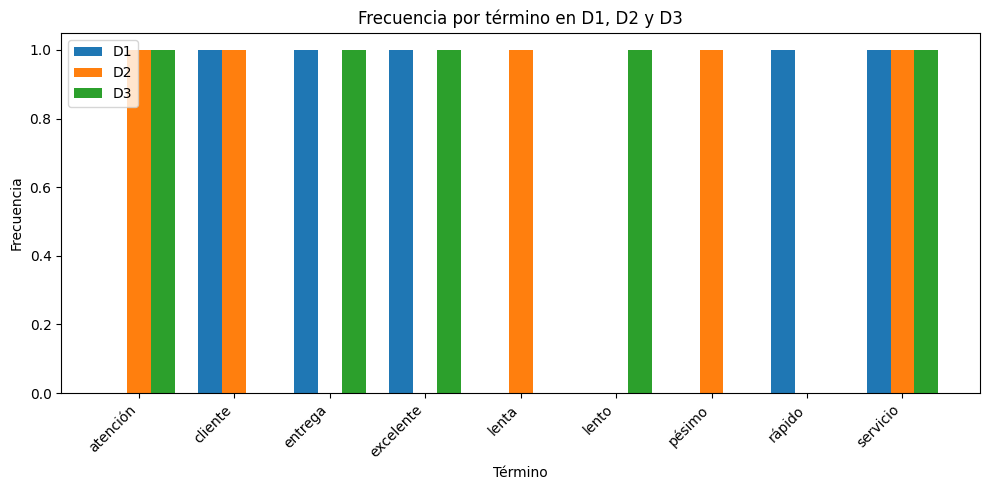

In [73]:
import matplotlib.pyplot as plt

terminos = V_filtrado
posiciones = list(range(len(terminos)))
ancho = 0.25

plt.figure(figsize=(10, 5))
plt.bar([p - ancho for p in posiciones], [tf[0].get(t, 0) for t in terminos], width=ancho, label="D1")
plt.bar(posiciones, [tf[1].get(t, 0) for t in terminos], width=ancho, label="D2")
plt.bar([p + ancho for p in posiciones], [tf[2].get(t, 0) for t in terminos], width=ancho, label="D3")
plt.title("Frecuencia por término en D1, D2 y D3")
plt.xlabel("Término")
plt.ylabel("Frecuencia")
plt.xticks(posiciones, terminos, rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Retos opcionales

### Reto 1. Agregar un cuarto comentario con HTML

Lo pruebo aparte para no cambiar las métricas del corpus principal.

In [74]:
comentario_extra = "<p>La <b>atención</b> fue buena y la entrega rápida.</p>"
corpus_extra = corpus + [comentario_extra]
docs_extra = [normalizar(d) for d in corpus_extra]
tokens_extra = [d.split() for d in docs_extra]

N_extra = sum(len(t) for t in tokens_extra)
V_extra = set()
for t in tokens_extra:
    V_extra = V_extra | set(t)
V_filtrado_extra = sorted(V_extra - S)

print("Comentario extra normalizado:", docs_extra[3])
print("N original =", N, "| N con el cuarto comentario =", N_extra)
print("|V| original =", len(V), "| |V| con el cuarto comentario =", len(V_extra))
print("|V_filtrado| original =", len(V_filtrado), "| |V_filtrado| con el cuarto comentario =", len(V_filtrado_extra))

Comentario extra normalizado: la atención fue buena y la entrega rápida
N original = 33 | N con el cuarto comentario = 41
|V| original = 18 | |V| con el cuarto comentario = 21
|V_filtrado| original = 9 | |V_filtrado| con el cuarto comentario = 12


### Reto 2. Comparar con stopwords de NLTK

Esta parte descarga el recurso de stopwords en español. En Colab se puede ejecutar directamente.

In [75]:
import nltk
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [76]:
from nltk.corpus import stopwords

stopwords_es = set(stopwords.words("spanish"))
S_nltk = set(V) & stopwords_es
V_filtrado_nltk = sorted(set(V) - stopwords_es)

print("Vocabulario filtrado con las stopwords de la práctica:", V_filtrado)
print("Stopwords de NLTK presentes en V:", sorted(S_nltk))
print("Vocabulario filtrado con NLTK:", V_filtrado_nltk)
print("|V_filtrado| con la práctica =", len(V_filtrado))
print("|V_filtrado| con NLTK =", len(V_filtrado_nltk))

Vocabulario filtrado con las stopwords de la práctica: ['atención', 'cliente', 'entrega', 'excelente', 'lenta', 'lento', 'pésimo', 'rápido', 'servicio']
Stopwords de NLTK presentes en V: ['al', 'de', 'el', 'en', 'es', 'la', 'muy', 'pero', 'y']
Vocabulario filtrado con NLTK: ['atención', 'cliente', 'entrega', 'excelente', 'lenta', 'lento', 'pésimo', 'rápido', 'servicio']
|V_filtrado| con la práctica = 9
|V_filtrado| con NLTK = 9


### Reto 3. Aplicar stemming en español

In [77]:
from nltk.stem.snowball import SnowballStemmer

stemmer = SnowballStemmer("spanish")
V_stem = sorted({stemmer.stem(palabra) for palabra in V_filtrado})
print("Vocabulario original:", V_filtrado)
print("Vocabulario con stemming:", V_stem)
print("Tamaño después del stemming:", len(V_stem))
assert len(V_stem) == 8

Vocabulario original: ['atención', 'cliente', 'entrega', 'excelente', 'lenta', 'lento', 'pésimo', 'rápido', 'servicio']
Vocabulario con stemming: ['atencion', 'client', 'entreg', 'excelent', 'lent', 'pesim', 'rap', 'servici']
Tamaño después del stemming: 8
